# Enterprise Data Architecture & Reconciliation

**Question for the CFO:** *How much genuine revenue, in USD, did we earn from our currently active customers, how did it change month by month, and which customers are worth the most?*

**Pipeline:** Accounts DB (SQL) → Server logs (regex) → Exchange rates (forward-fill) → merge → USD revenue → dashboard.
Every step prints row counts so no transaction disappears silently.

In [1]:
import time, sqlite3, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

T0 = time.time()
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

## Phase 1: SQL extraction of currently Active customers

**Data problem:** the `users` table is a *history of status changes* (47,464 rows for 25,000 customers), not a snapshot. A customer can be `Pending → Active → Suspended`.
**Decision:** rank each customer's rows by `updated_at` (newest first) with a window function `ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY updated_at DESC)`, keep rank 1 (the *latest* row), and only then filter on `status = 'Active'`.
Filtering on `Active` *before* ranking would be a bug: it would keep customers who were Active once but are now Suspended.

In [2]:
conn = sqlite3.connect("../data/enterprise_database.db")

# Profile the raw table first
print(pd.read_sql("SELECT COUNT(*) AS total_rows, COUNT(DISTINCT user_id) AS unique_users FROM users", conn))
print(pd.read_sql("SELECT status, COUNT(*) AS n FROM users GROUP BY status", conn))

query = '''
WITH ranked AS (
    SELECT user_id, name, status, updated_at,
           ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY updated_at DESC) AS rn
    FROM users
)
SELECT user_id, name, status, updated_at
FROM ranked
WHERE rn = 1            -- latest status per customer
  AND status = 'Active' -- ...and only if that latest status is Active
'''
df_active_users = pd.read_sql(query, conn)
conn.close()

# Validation
latest_all = pd.read_sql("SELECT COUNT(DISTINCT user_id) n FROM users", sqlite3.connect("../data/enterprise_database.db"))["n"][0]
print(f"\nCustomers (latest status of any kind): {latest_all:,}")
print(f"Currently Active customers:             {len(df_active_users):,}")
assert df_active_users["user_id"].is_unique, "duplicate users found!"
assert (df_active_users["status"] == "Active").all()
df_active_users.head()

   total_rows  unique_users
0       47464         25000
      status      n
0     Active  17582
1    Pending  25000
2  Suspended   4882

Customers (latest status of any kind): 25,000
Currently Active customers:             14,183


,user_id,name,status,updated_at
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00


**Check:** one row per customer (`is_unique` passes), every row is `Active`. The count is lower than the number of customers who *ever* had an Active row, because many were later Suspended.

In [3]:
# Cross-check the SQL result independently with pandas (vectorised, no loops)
raw = pd.read_sql("SELECT * FROM users", sqlite3.connect("../data/enterprise_database.db"))
latest = raw.sort_values("updated_at").groupby("user_id").tail(1)
ever_active = raw.loc[raw.status == "Active", "user_id"].nunique()
check = set(latest.loc[latest.status == "Active", "user_id"])
print("SQL result matches pandas cross-check:", check == set(df_active_users.user_id))
print(f"Ever Active: {ever_active:,}  vs  Currently Active: {len(df_active_users):,}  "
      f"(-> {ever_active - len(df_active_users):,} customers were Active once but changed status later)")

SQL result matches pandas cross-check: True
Ever Active: 17,582  vs  Currently Active: 14,183  (-> 3,399 customers were Active once but changed status later)


## Phase 2: Regex extraction from raw server logs

**Data problem:** each line is free text with the transaction buried in a JSON-like payload, e.g.
`[2023-03-15 00:00:00] INFO: Transaction processed. payload={"u":"U-19484", "item_code":"PRD-874", "eur_val":3404.44}`
Error lines (`ERROR`) use a different key (`failed_val`, not `eur_val`) and are *not* revenue.

**Decision:** read the file as one text column, drop `ERROR` lines, then extract the four fields with one vectorised `str.extract` using named groups, and cast to proper types (datetime / float).

In [4]:
logs = pd.read_csv("../data/server_logs.txt")            # single column: Raw_Server_Log
n_raw = len(logs)
print(f"Raw log lines: {n_raw:,}")
print(logs["Raw_Server_Log"].str.extract(r"\] (\w+):")[0].value_counts().to_string())

# Step 1: drop ERROR lines (failed events are not genuine revenue)
is_error = logs["Raw_Server_Log"].str.contains("ERROR", regex=False)
valid_logs = logs.loc[~is_error].copy()
print(f"\nERROR lines dropped: {is_error.sum():,}  -> remaining: {len(valid_logs):,}")

# Step 2: regex with named groups
pattern = (r"\[(?P<Date>\d{4}-\d{2}-\d{2})[^\]]*\]"
           r".*?\"u\":\"(?P<User_ID>U-\d+)\""
           r".*?\"item_code\":\"(?P<Product_ID>PRD-\d+)\""
           r".*?\"eur_val\":(?P<Euro_Value>[\d.]+)")
extracted_data = valid_logs["Raw_Server_Log"].str.extract(pattern)

# Step 3: types
extracted_data["Date"] = pd.to_datetime(extracted_data["Date"], format="%Y-%m-%d")
extracted_data["Euro_Value"] = extracted_data["Euro_Value"].astype(float)

# Validation: every non-error line must parse
unparsed = extracted_data.isna().any(axis=1).sum()
print(f"Lines that failed to parse: {unparsed}")
assert unparsed == 0
assert len(extracted_data) == n_raw - is_error.sum()
extracted_data = extracted_data.reset_index(drop=True)
print(f"extracted_data rows: {len(extracted_data):,}")
print(extracted_data.dtypes.to_string())
extracted_data.head()

Raw log lines: 100,000
0
INFO     94902
ERROR     5098

ERROR lines dropped: 5,098  -> remaining: 94,902
Lines that failed to parse: 0
extracted_data rows: 94,902
Date          datetime64[us]
User_ID                  str
Product_ID               str
Euro_Value           float64


,Date,User_ID,Product_ID,Euro_Value
0,2023-03-15,U-19484,PRD-874,"3,404.44"
1,2023-05-09,U-18932,PRD-905,"3,406.21"
2,2023-10-21,U-15882,PRD-284,164.08
3,2023-01-10,U-22781,PRD-665,26.80
4,2023-05-23,U-13348,PRD-589,"4,964.77"


## Phase 3: Financial reconciliation & merging

**Data problem (temporal gap):** `daily_exchange_rates.csv` has a row for every calendar day, but 104 days (28.5%) have a blank rate (market closed). In this file the blanks fall on **every Friday and Saturday** (not Sat/Sun as the brief's wording suggests), so the rate carried forward is Thursday's. An inner join on the date would silently drop every transaction on those days (about 28% of the data).
**Decision:** convert the date column to a real datetime, forward-fill (`ffill`) so the last published rate carries over the gap, and use a **left join** from transactions, so no valid transaction can disappear. I check that no rate is left missing.

In [5]:
rates = pd.read_csv("../data/daily_exchange_rates.csv")
print(rates.dtypes.to_string())
rates["Date"] = pd.to_datetime(rates["Date"], format="%Y-%m-%d")      # text -> real date
rates = rates.sort_values("Date").reset_index(drop=True)                # ffill needs chronological order

missing_before = rates["EUR_to_USD"].isna().sum()
print(f"\nDays in rate table: {len(rates)}, missing rates: {missing_before} "
      f"({missing_before/len(rates):.1%})")
print("Missing rates fall on weekdays:", rates.loc[rates.EUR_to_USD.isna(), "Date"].dt.day_name().value_counts().to_dict())

rates["EUR_to_USD"] = rates["EUR_to_USD"].ffill()
print("Missing after ffill:", rates["EUR_to_USD"].isna().sum())
assert rates["EUR_to_USD"].notna().all()

# Do all transaction dates sit inside the rate table's calendar?
print("Log date range  :", extracted_data.Date.min().date(), "->", extracted_data.Date.max().date())
print("Rate date range :", rates.Date.min().date(), "->", rates.Date.max().date())

Date              str
EUR_to_USD    float64

Days in rate table: 365, missing rates: 104 (28.5%)
Missing rates fall on weekdays: {'Friday': 52, 'Saturday': 52}
Missing after ffill: 0
Log date range  : 2023-01-01 -> 2023-12-31
Rate date range : 2023-01-01 -> 2023-12-31


In [6]:
n_tx = len(extracted_data)

# --- Show WHY ffill + left join matters: what an inner join on the raw rates would have lost
raw_rates = pd.read_csv("../data/daily_exchange_rates.csv", parse_dates=["Date"]).dropna()
naive = extracted_data.merge(raw_rates, on="Date", how="inner")
print(f"Naive inner join on raw rates keeps {len(naive):,} of {n_tx:,} rows -> LOSES {n_tx-len(naive):,} ({1-len(naive)/n_tx:.1%})")

# --- Correct merge 1: transactions + rates (left join, many-to-one)
df = extracted_data.merge(rates, on="Date", how="left", validate="many_to_one")
assert len(df) == n_tx and df["EUR_to_USD"].notna().all()
print(f"After rate merge: {len(df):,} rows (nothing lost, no missing rates)")

# --- Merge 2: keep only ACTIVE customers (inner join on User_ID), one row per user so no fan-out
df_final = df.merge(df_active_users[["user_id", "name"]], left_on="User_ID", right_on="user_id",
                    how="inner", validate="many_to_one").drop(columns="user_id")
dropped = n_tx - len(df_final)
print(f"After active-customer filter: {len(df_final):,} rows "
      f"({dropped:,} transactions belong to non-active / unknown customers and are excluded on purpose)")

# --- Revenue in USD at the rate of the transaction day
df_final["USD_Revenue"] = df_final["Euro_Value"] * df_final["EUR_to_USD"]
df_final["Month"] = df_final["Date"].dt.to_period("M")
df_final.head()

Naive inner join on raw rates keeps 67,918 of 94,902 rows -> LOSES 26,984 (28.4%)
After rate merge: 94,902 rows (nothing lost, no missing rates)
After active-customer filter: 53,899 rows (41,003 transactions belong to non-active / unknown customers and are excluded on purpose)


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD,name,USD_Revenue,Month
0,2023-03-15,U-19484,PRD-874,"3,404.44",1.18,User_U-19484,"4,011.22",2023-03
1,2023-10-21,U-15882,PRD-284,164.08,1.08,User_U-15882,176.44,2023-10
2,2023-01-10,U-22781,PRD-665,26.80,1.13,User_U-22781,30.21,2023-01
3,2023-10-20,U-22062,PRD-363,48.63,1.08,User_U-22062,52.29,2023-10
4,2023-12-02,U-22146,PRD-223,960.60,1.07,User_U-22146,"1,024.14",2023-12


In [7]:
# Reconciliation: every valid transaction is either in df_final or explicitly excluded (non-active customer)
all_users = pd.read_sql("SELECT DISTINCT user_id FROM users", sqlite3.connect("../data/enterprise_database.db"))["user_id"]
unknown = (~df["User_ID"].isin(all_users)).sum()
non_active = (df["User_ID"].isin(all_users) & ~df["User_ID"].isin(df_active_users.user_id)).sum()

recon = pd.DataFrame({
    "Rows": [len(logs), -is_error.sum(), n_tx, -non_active, -unknown, len(df_final)],
}, index=["Raw log lines", "less: ERROR lines", "Valid transactions", "less: customer not currently Active",
          "less: customer not in accounts DB", "df_final (active customers)"])
print(recon.to_string())
assert n_tx - non_active - unknown == len(df_final)

eur_total_all = df["Euro_Value"].sum()
print(f"\nEUR, all valid transactions : {eur_total_all:,.2f}")
print(f"EUR, active customers (final): {df_final['Euro_Value'].sum():,.2f}")
print(f"USD revenue, active customers: {df_final['USD_Revenue'].sum():,.2f}")
print(f"Implied avg rate: {df_final['USD_Revenue'].sum()/df_final['Euro_Value'].sum():.4f}")
assert (df_final["USD_Revenue"] > 0).all()

                                       Rows
Raw log lines                        100000
less: ERROR lines                     -5098
Valid transactions                    94902
less: customer not currently Active  -41003
less: customer not in accounts DB         0
df_final (active customers)           53899

EUR, all valid transactions : 237,775,609.55
EUR, active customers (final): 134,958,287.20
USD revenue, active customers: 148,274,622.91
Implied avg rate: 1.0987


## Phase 4: Aggregation & CFO dashboard

Label   USD_Revenue
  Jan 12,841,761.38
  Feb 11,436,130.90
  Mar 12,348,931.84
  Apr 12,015,376.19
  May 12,333,644.45
  Jun 12,084,355.82
  Jul 12,444,163.58
  Aug 12,812,730.66
  Sep 12,228,952.05
  Oct 12,501,330.36
  Nov 12,588,223.09
  Dec 12,639,022.60

   User_ID          name  USD_Revenue
0  U-06582  User_U-06582    40,050.99
1  U-23313  User_U-23313    39,555.81
2  U-03805  User_U-03805    39,529.95
3  U-20018  User_U-20018    38,649.97
4  U-06489  User_U-06489    38,629.14


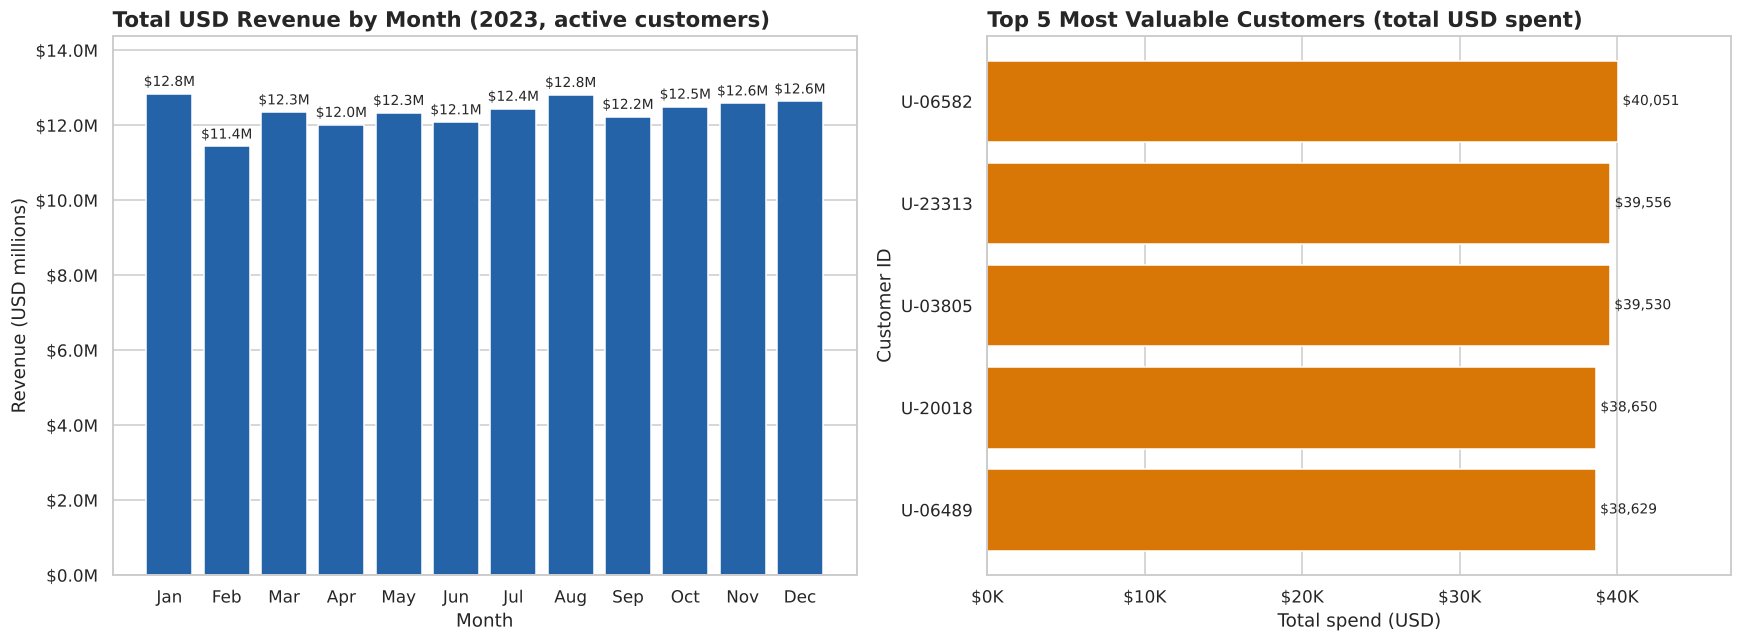

In [8]:
monthly = (df_final.groupby("Month", as_index=False)["USD_Revenue"].sum()
           .assign(Label=lambda d: d["Month"].dt.strftime("%b")))
top5 = (df_final.groupby(["User_ID", "name"], as_index=False)["USD_Revenue"].sum()
        .nlargest(5, "USD_Revenue").reset_index(drop=True))
assert abs(monthly.USD_Revenue.sum() - df_final.USD_Revenue.sum()) < 1e-6   # months add up to the total

money_m = FuncFormatter(lambda x, _: f"${x/1e6:,.1f}M")
BLUE, ORANGE = "#2563a8", "#d97706"

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
bars = ax.bar(monthly["Label"], monthly["USD_Revenue"], color=BLUE)
ax.set_title("Total USD Revenue by Month (2023, active customers)", fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue (USD millions)")
ax.yaxis.set_major_formatter(money_m)
ax.bar_label(bars, labels=[f"${v/1e6:.1f}M" for v in monthly.USD_Revenue], padding=3, fontsize=9)
ax.set_ylim(0, monthly.USD_Revenue.max()*1.12)
ax.grid(axis="x", visible=False)

ax = axes[1]
labels = top5["User_ID"]
bars = ax.barh(labels[::-1], top5["USD_Revenue"][::-1], color=ORANGE)
ax.set_title("Top 5 Most Valuable Customers (total USD spent)", fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Total spend (USD)"); ax.set_ylabel("Customer ID")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x/1e3:,.0f}K"))
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in top5["USD_Revenue"][::-1]], padding=3, fontsize=9)
ax.set_xlim(0, top5.USD_Revenue.max()*1.18)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.savefig("cfo_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

print(monthly[["Label", "USD_Revenue"]].to_string(index=False))
print()
print(top5.to_string())

## Summary of decisions, data problems and validation

| # | Data problem found | How I handled it | How I checked it |
|---|---|---|---|
| 1 | `users` is a change history (multiple rows per customer) | SQL window function `ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY updated_at DESC)`, keep latest, **then** filter `Active` | `user_id` unique; matches an independent pandas `groupby().tail(1)` check |
| 2 | Customers who were Active once but later Suspended | Excluded; the latest status decides | Count of "ever active" vs "currently active" |
| 3 | Transactions buried in free-text logs, with `ERROR` lines using `failed_val` | Dropped `ERROR` lines; one vectorised `str.extract` with named groups; cast to datetime/float | 0 unparsed lines; rows = raw − errors |
| 4 | Exchange-rate gaps (104 blank days, all Fri/Sat) | Converted date to datetime, sorted, `ffill()`; left join with `validate="many_to_one"` | 0 missing rates after fill; inner join would have lost many rows (shown above) |
| 5 | Transactions from customers who are not Active | Excluded on purpose via inner join to `df_active_users` | Reconciliation table accounts for every row |
| 6 | Efficiency | Only vectorised pandas / SQL; no loops, `iterrows` or row-wise `apply` | Runtime printed below |

In [9]:
elapsed = time.time() - T0
print(f"Total notebook runtime: {elapsed:.1f} seconds (limit: 120 s)")
assert elapsed < 120

Total notebook runtime: 1.2 seconds (limit: 120 s)
